# MFT — итоговый портфель и проверка целей

Капитал **3 000 000 CNY**; годовая доходность **>20%**, Sharpe **>1,5**, просадка **<15%**; win rate >50% необязателен.

Train: 2015–2018. Validation: 2019 (используется для отбора). Evaluation: полный 2020 и доступная часть 2021 до 18 октября. Это ретроспективное исследование, не полностью нетронутый holdout.

Правила выбраны до первой оценки этого портфеля на 2020–2021. После просмотра test состав и пороги не меняются. Контроль маржи был исправлен после первоначального расчёта; первоначальные метрики сохранены. Прохождение целей на validation не доказывает работоспособность стратегии.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image, FileLink
from src.final_project import run

out = Path('reports/final_portfolio')
config = json.loads(Path('configs/final_portfolio.json').read_text())
assert config['evaluation_used_for_selection'] is False
assert config['risk']['initial_capital'] == 3_000_000
print('Проверено конфигураций:', config['configurations_searched'])
print('Замороженных инструментов:', len(config['candidates']))
display(pd.DataFrame(config['candidates']))

Проверено конфигураций: 17290
Замороженных инструментов: 14


,symbol,family,timeframe,lookback,holding,quantile,side,candidate_id,train_threshold
0,NI,daily_trend,5,20,0,0.50,short,NI:daily_trend:5,0.049883
1,AU,daily_reversal,5,60,0,0.50,long,AU:daily_reversal:5,0.025293
2,T,opening_reversal,5,1,0,0.80,long,T:opening_reversal:5,0.001009
3,RU,daily_reversal,5,20,0,0.50,short,RU:daily_reversal:5,0.052945
4,OI,reversal,30,1,1,0.95,short,OI:reversal:30,0.005355
5,CY,reversal,30,1,0,0.80,short,CY:reversal:30,0.002740
6,SM,reversal,5,1,4,0.95,short,SM:reversal:5,0.005639
7,AP,momentum,5,4,0,0.95,long,AP:momentum:5,0.008898
8,ZN,daily_opening_momentum,5,1,0,0.50,short,ZN:daily_opening_momentum:5,0.005426
9,JD,daily_trend,5,20,0,0.50,short,JD:daily_trend:5,0.035225


## 1. Пересчитать весь финальный эксперимент

Эта ячейка запускает код из `src/`, пересчитывает ledger, minute-close equity, отдельный 2020 год, стресс-сценарии и bootstrap, сохраняет CSV/Markdown/PDF. Она **не** перезапускает поиск и не перевыбирает стратегию. Расчёт может занять несколько минут. Сигналы входят по следующему open, комиссии и tick применяются на обеих сторонах.

In [2]:
results = run()
display(results[['period', 'annualized_return_pct', 'sharpe', 'max_drawdown_pct', 'trades', 'win_rate_pct', 'all_required_pass']])

train {'days': 1054, 'elapsed_days': 1461, 'final_equity_cny': np.float64(7087884.699500068), 'total_return_pct': np.float64(136.26282331666894), 'annualized_return_pct': np.float64(23.979205053918196), 'sharpe': np.float64(2.025782452124968), 'max_drawdown_pct': np.float64(9.073540055800377), 'trades': 3090, 'win_rate_pct': np.float64(52.7831715210356), 'max_margin_pct': np.float64(59.879109781646655), 'margin_breaches': 0, 'forced_margin_exits': 1, 'drawdown_marks': 'minute_close', 'primary_pass': True, 'all_required_pass': True, 'period': 'train', 'start': '2015-01-01', 'end': Timestamp('2018-12-31 23:59:59'), 'complete_calendar_year': False}


validation {'days': 261, 'elapsed_days': 365, 'final_equity_cny': np.float64(3660111.2105000257), 'total_return_pct': np.float64(22.00370701666752), 'annualized_return_pct': np.float64(22.020327497281734), 'sharpe': np.float64(1.6735534132300356), 'max_drawdown_pct': np.float64(10.56164740333394), 'trades': 612, 'win_rate_pct': np.float64(53.431372549019606), 'max_margin_pct': np.float64(59.99491655996738), 'margin_breaches': 0, 'forced_margin_exits': 10, 'drawdown_marks': 'minute_close', 'primary_pass': True, 'all_required_pass': True, 'period': 'validation', 'start': '2019-01-01', 'end': Timestamp('2019-12-31 23:59:59'), 'complete_calendar_year': True}


test {'days': 470, 'elapsed_days': 657, 'final_equity_cny': np.float64(1780478.5335000567), 'total_return_pct': np.float64(-40.650715549998104), 'annualized_return_pct': np.float64(-25.177279334288528), 'sharpe': np.float64(-1.3563556272517288), 'max_drawdown_pct': np.float64(46.689654808144), 'trades': 2168, 'win_rate_pct': np.float64(48.38560885608857), 'max_margin_pct': np.float64(59.99918659611896), 'margin_breaches': 0, 'forced_margin_exits': 79, 'drawdown_marks': 'minute_close', 'primary_pass': False, 'all_required_pass': False, 'period': 'test', 'start': '2020-01-01', 'end': Timestamp('2021-10-18 15:00:00'), 'complete_calendar_year': False}


2020 {'days': 262, 'elapsed_days': 366, 'final_equity_cny': np.float64(2888446.5545000266), 'total_return_pct': np.float64(-3.7184481833324456), 'annualized_return_pct': np.float64(-3.7109715801554866), 'sharpe': np.float64(-0.09742508838273696), 'max_drawdown_pct': np.float64(16.20124371147297), 'trades': 1013, 'win_rate_pct': np.float64(48.864758144126355), 'max_margin_pct': np.float64(59.99234131243776), 'margin_breaches': 0, 'forced_margin_exits': 32, 'drawdown_marks': 'minute_close', 'primary_pass': False, 'all_required_pass': False, 'period': '2020', 'start': '2020-01-01', 'end': Timestamp('2020-12-31 23:59:59'), 'complete_calendar_year': True}


2021_partial {'days': 208, 'elapsed_days': 291, 'final_equity_cny': np.float64(1848158.0005000327), 'total_return_pct': np.float64(-38.39473331666557), 'annualized_return_pct': np.float64(-45.55752525880955), 'sharpe': np.float64(-2.914351529353343), 'max_drawdown_pct': np.float64(41.76811891548974), 'trades': 1147, 'win_rate_pct': np.float64(47.95117698343505), 'max_margin_pct': np.float64(59.99995695082395), 'margin_breaches': 0, 'forced_margin_exits': 49, 'drawdown_marks': 'minute_close', 'primary_pass': False, 'all_required_pass': False, 'period': '2021_partial', 'start': '2021-01-01', 'end': Timestamp('2021-10-18 15:00:00'), 'complete_calendar_year': False}


PDF: reports/final_portfolio/MFT_Project_Report.pdf


,period,annualized_return_pct,sharpe,max_drawdown_pct,trades,win_rate_pct,all_required_pass
0,train,23.979205,2.025782,9.073540,3090,52.783172,True
1,validation,22.020327,1.673553,10.561647,612,53.431373,True
2,test,-25.177279,-1.356356,46.689655,2168,48.385609,False
3,2020,-3.710972,-0.097425,16.201244,1013,48.864758,False
4,2021_partial,-45.557525,-2.914352,41.768119,1147,47.951177,False


## 2. Сверить требования с полным 2020 годом

Годовая доходность — CAGR капитала, Sharpe — дневные доходности счёта с нулевыми днями. Просадка включает начальные 3 млн и minute-close marks; intraminute extremes неизвестны. Результат 2019 не подменяет контрольный год.

In [3]:
evaluation = results.set_index('period').loc['2020']
goals = pd.DataFrame([
    {'metric': 'Annualized return, %', 'required': '>20', 'actual': evaluation.annualized_return_pct, 'passed': evaluation.annualized_return_pct > 20},
    {'metric': 'Sharpe', 'required': '>1.5', 'actual': evaluation.sharpe, 'passed': evaluation.sharpe > 1.5},
    {'metric': 'Minute-close max DD, %', 'required': '<15', 'actual': evaluation.max_drawdown_pct, 'passed': evaluation.max_drawdown_pct < 15},
    {'metric': 'Win rate, % (optional)', 'required': '>50', 'actual': evaluation.win_rate_pct, 'passed': evaluation.win_rate_pct > 50},
])
display(goals)
print('Все обязательные цели:', bool(goals.iloc[:3].passed.all()))
print('Нельзя объявлять успех по validation, если evaluation не проходит.')

,metric,required,actual,passed
0,"Annualized return, %",>20,-3.710972,False
1,Sharpe,>1.5,-0.097425,False
2,"Minute-close max DD, %",<15,16.201244,False
3,"Win rate, % (optional)",>50,48.864758,False


Все обязательные цели: False
Нельзя объявлять успех по validation, если evaluation не проходит.


## 3. Капитал, маржа и объём

Целые лоты; оценочный риск 1% капитала — не стоп-лосс. Волатильность только прошлых дней. Маржа сценарная 20% notional, бюджет 30% на инструмент/60% суммарно. Лоты ограничены 1% уже известного объёма сигнального бара и OI. Контроль маржи после minute-close может принудительно закрывать крупнейшую позицию с актуальной ценой. Ledger включает реальные для этой модели выходные цены и комиссии.

Объём **будущих** минут не используется для отбора: только для диагностики исполнимости после расчёта.

In [4]:
display(results[['period', 'max_margin_pct', 'margin_breaches', 'forced_margin_exits']])
ledger = pd.read_csv(out / 'trades_2020.csv')
accepted = ledger[ledger.accepted]
assert abs(3_000_000 + accepted.account_pnl_cny.sum() - evaluation.final_equity_cny) < 1e-5
print('Сверка конечного капитала с ledger: OK')
print('Пропуски:', ledger.loc[~ledger.accepted, 'skip_reason'].value_counts().to_dict())
audit = pd.read_csv(out / 'execution_volume_audit.csv')
display(audit.groupby('period').agg(trades=('lots', 'size'), entry_above_5pct=('entry_participation', lambda x: (x > .05).sum()), exit_above_5pct=('exit_participation', lambda x: (x > .05).sum())))

,period,max_margin_pct,margin_breaches,forced_margin_exits
0,train,59.879110,0,1
1,validation,59.994917,0,10
2,test,59.999187,0,79
3,2020,59.992341,0,32
4,2021_partial,59.999957,0,49


Сверка конечного капитала с ledger: OK
Пропуски: {'size_zero': 32}


,trades,entry_above_5pct,exit_above_5pct
period,,,
test,2168,628,809
train,3090,1144,1175
validation,612,229,242


## 4. Equity curve, годовая статистика, стресс и неопределённость

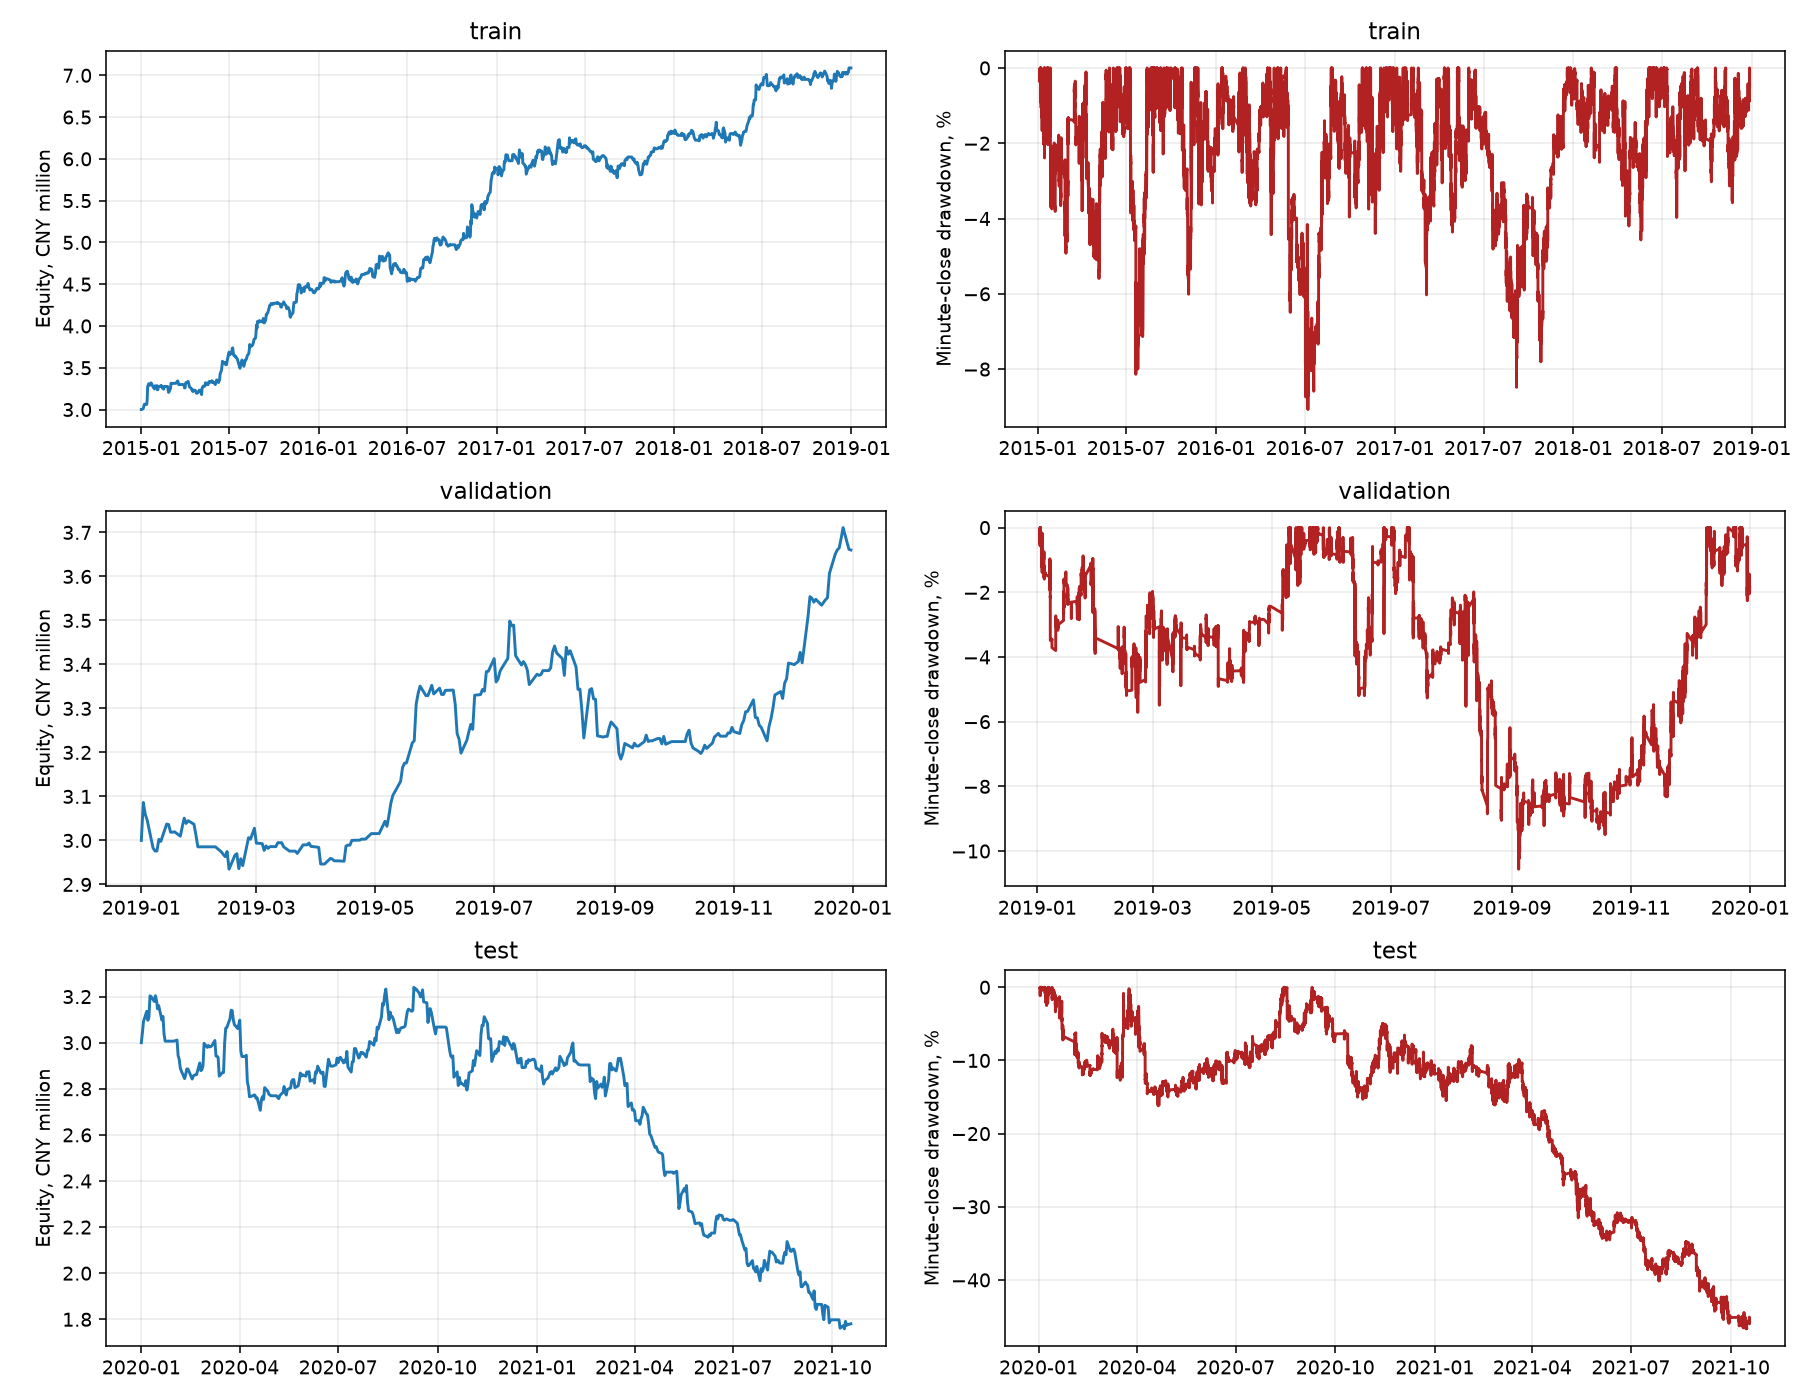

,period,year,instrument,trades,pnl_cny,mean_unit_net_bps,median_unit_net_bps,win_rate_pct
0,train,2015,AL,52,102691.0000,10.224262,1.434588,50.000000
1,train,2015,AU,104,87650.0000,3.539991,2.089748,50.961538
2,train,2015,CF,37,96340.5000,11.937685,14.533030,62.162162
3,train,2015,JD,113,282939.5685,6.906217,-0.270259,49.557522
4,train,2015,NI,86,369392.0000,20.666107,16.752225,56.976744
...,...,...,...,...,...,...,...,...
88,test,2021,SF,76,-627131.0000,-68.638869,-79.817789,35.526316
89,test,2021,SM,163,83191.0000,5.686448,-3.375747,49.693252
90,test,2021,SN,186,-48004.0000,-1.575985,4.984854,54.838710
91,test,2021,T,9,-4810.0000,-5.094009,-6.086605,44.444444


,scenario,annualized_return_pct,sharpe,max_drawdown_pct,all_required_pass
1,base,-3.710972,-0.097425,16.201244,False
4,3_ticks_per_side,-49.933110,-3.323060,52.781332,False
7,fees_x1.5,-12.470652,-0.572328,18.824092,False
10,participation_0.5pct,-6.129375,-0.242681,17.459586,False
13,margin_40pct,-2.288534,-0.102457,20.143819,False
16,risk_half,-4.785725,-0.364492,13.140458,False


,period,return_low_pct,return_high_pct,sharpe_low,sharpe_high
0,train,11.289950,37.572890,1.069511,2.930547
1,validation,-5.601727,57.014937,-0.412513,3.600499
2,test,-42.379895,-1.108567,-2.722539,0.046619
3,2020,-34.131686,41.620039,-1.949287,1.849189
4,2021_partial,-63.541442,-18.734196,-5.017876,-0.940785


In [5]:
display(Image(filename=str(out / 'equity_drawdown.png')))
display(pd.read_csv(out / 'yearly_instrument.csv'))
sensitivity = pd.read_csv(out / 'sensitivity.csv')
display(sensitivity[sensitivity.period.eq('2020')][['scenario', 'annualized_return_pct', 'sharpe', 'max_drawdown_pct', 'all_required_pass']])
display(pd.read_csv(out / 'confidence.csv'))

## 5. Почему результат не равен готовой торговой стратегии

17 290 конфигураций создают selection bias. Низкие индивидуальные t-статистики не являются подтверждённой значимостью. Комиссии из Excel 2026 используются буквально как сценарий, не восстановлены исторически. Ночные блоки обрываются на полуночи; mixed-symbol дни и неполные блоки отсекаются ex post. End-of-block выход может оказаться ранним из-за пропусков CSV. Нет bid/ask, очередей, отдельного expiring-contract ряда и точной исторической маржи. Ограничение прошлого объёма не гарантирует следующий fill. Bootstrap условен на выбранных правилах и не учитывает весь поиск.

Из отчёта Alexandr Khozhanov взяты исследовательские идеи, а не чужие результаты. Численный успех на 2019 не переносится автоматически на test. Следующий независимый контроль требует новых, не просмотренных данных и более точной модели исполнения.

In [6]:
import subprocess, sys
check = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'], capture_output=True, text=True)
print(check.stdout + check.stderr)
assert check.returncode == 0
print('Отчёт и PDF:')
display(FileLink(str(out / 'REPORT.md')))
display(FileLink(str(out / 'MFT_Project_Report.pdf')))
display(FileLink(str(out / 'manifest.json')))

test_bps_and_both_slippage_sides (test_opening_move_final.BacktestTests.test_bps_and_both_slippage_sides) ... ok
test_first_loss_drawdown_includes_initial_capital (test_opening_move_final.BacktestTests.test_first_loss_drawdown_includes_initial_capital) ... ok
test_previous_close_retains_mixed_day_and_missing_open_rejected (test_opening_move_final.BacktestTests.test_previous_close_retains_mixed_day_and_missing_open_rejected) ... ok
test_simulation_reconciles_and_enforces_margin_without_minimum_one (test_opening_move_final.BacktestTests.test_simulation_reconciles_and_enforces_margin_without_minimum_one) ... ok
test_simultaneous_positions_share_margin_and_entry_cost_budget (test_opening_move_final.BacktestTests.test_simultaneous_positions_share_margin_and_entry_cost_budget) ... ok
test_training_threshold_ignores_future (test_opening_move_final.BacktestTests.test_training_threshold_ignores_future) ... ok
test_fee_units (test_portfolio_engine.PortfolioTests.test_fee_units) ... ok
test_liqui

/home/egorzobkov/cmf/MFT_HW/reports/final_portfolio/REPORT.md

/home/egorzobkov/cmf/MFT_HW/reports/final_portfolio/MFT_Project_Report.pdf

/home/egorzobkov/cmf/MFT_HW/reports/final_portfolio/manifest.json